In [ ]:
import subprocess
from pathlib import Path
import h5py

DATA = Path.home() / "EMsoft_data"   # to samo co EMdatapathname w konfiguracji

def make_template(program):
    """Tworzy szablon namelisty (to samo co: program -t)."""
    subprocess.run([program, "-t"], cwd=DATA, check=True)

def run_emsoft(program, nml_name):
    """Uruchamia program z gotowym plikiem .nml leżącym w DATA."""
    wynik = subprocess.run([program, nml_name], cwd=DATA,
                           capture_output=True, text=True)
    print(wynik.stdout[-2000:])      # ostatnie linie komunikatów programu
    if wynik.returncode != 0:
        print("BŁĄD:", wynik.stderr)

def pokaz_strukture(h5_name):
    """Wypisuje wszystkie grupy i zbiory danych w pliku wynikowym."""
    with h5py.File(DATA / h5_name, "r") as f:
        f.visit(print)

In [ ]:
import h5py, numpy as np
with h5py.File("/home/pz/EMsoft_data/KNO_ecp.h5", "r") as f:
    ecp = f["EMData/ECP/ECpatterns"][()]
print(ecp.shape, ecp.dtype)

kształt tablicy: (3, 261, 261)


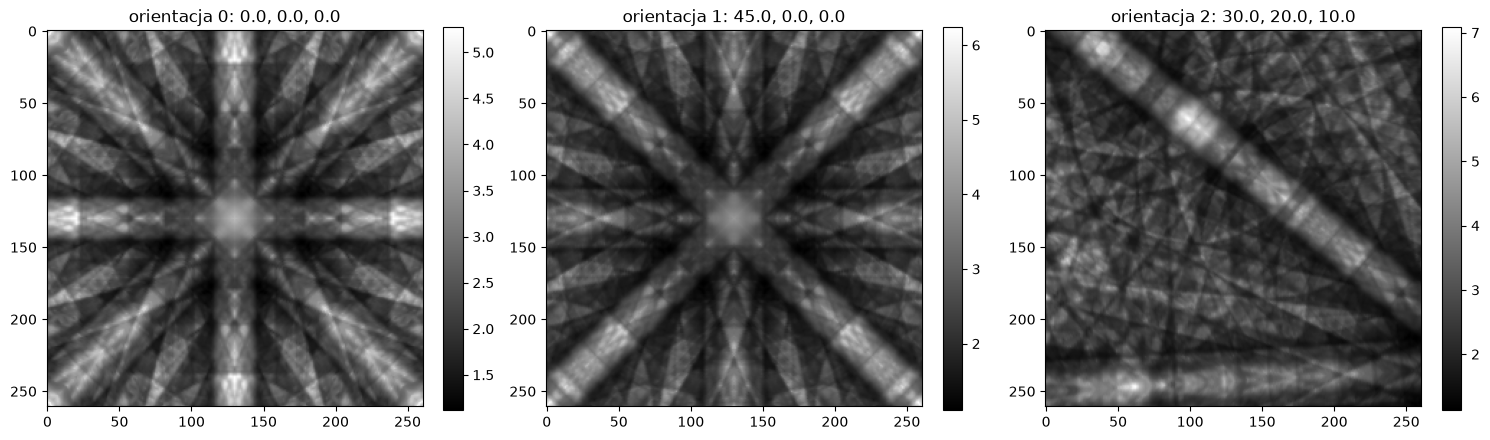

In [1]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

DATA = Path.home() / "EMsoft_data"

with h5py.File(DATA / "KNO_ecp.h5", "r") as f:
    ecp = np.squeeze(f["EMData/ECP/ECpatterns"][()])

print("kształt tablicy:", ecp.shape)

# Oś z liczbą orientacji jest tą najkrótszą; przenosimy ją na początek.
if ecp.ndim == 3:
    ecp = np.moveaxis(ecp, int(np.argmin(ecp.shape)), 0)
else:
    ecp = ecp[np.newaxis]             # jedna orientacja

# Podpisy bierzemy z angles.txt (od trzeciej linii są same kąty).
linie = (DATA / "angles.txt").read_text().splitlines()
katy = linie[2:]

n = ecp.shape[0]
fig, osie = plt.subplots(1, n, figsize=(5 * n, 4.5), squeeze=False)
for i, ax in enumerate(osie[0]):
    obraz = ax.imshow(ecp[i], cmap="gray")
    ax.set_title(f"orientacja {i}: {katy[i] if i < len(katy) else ''}")
    fig.colorbar(obraz, ax=ax, fraction=0.046)

plt.tight_layout()
plt.savefig("ecp_wszystkie.png", dpi=150)   # zapis do pliku obok skryptu
plt.show()